# Fondamentaux du machine learning : ACP, K-means et k plus proches voisins

**Auteur :** Jean Paguiyendou KOMBATE

Ce notebook applique trois algorithmes classiques, avec une méthodologie rigoureuse, à un jeu de données médicales public : le **diagnostic du cancer du sein (Wisconsin)**, 569 tumeurs décrites par 30 mesures issues d'images de cellules, classées bénignes ou malignes. Le jeu de données Iris sert de second exemple pour comparer les comportements.

| Technique | Type | Question posée |
|---|---|---|
| **ACP** (analyse en composantes principales) | Réduction de dimension | Peut-on résumer 30 variables en quelques axes sans perdre l'essentiel ? |
| **K-means** | Apprentissage non supervisé | Les données se regroupent-elles naturellement, et ces groupes correspondent-ils au diagnostic ? |
| **k plus proches voisins (k-NN)** | Apprentissage supervisé | Peut-on prédire le diagnostic, et avec quelle fiabilité ? |

**Bonnes pratiques mises en œuvre :** standardisation des variables, séparation entraînement/test **stratifiée**, choix des hyperparamètres par validation croisée **sur l'entraînement seul**, pipelines (aucune fuite d'information du test vers l'entraînement), métriques adaptées au contexte médical (sensibilité), incertitude des performances par validation croisée répétée, comparaison à un modèle de référence.

**Données :** intégrées à la bibliothèque scikit-learn (aucun fichier à télécharger).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, recall_score,
                             precision_score, roc_auc_score, RocCurveDisplay, silhouette_score,
                             adjusted_rand_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format
RANDOM_STATE = 42

## 1. Les données

In [2]:
bc = load_breast_cancer(as_frame=True)
X = bc.data
# Dans scikit-learn, la cible vaut 0 pour « malin » et 1 pour « bénin » : on la recode pour que 1 = malin (classe d'intérêt)
y = (bc.target == 0).astype(int).rename("malin")
print(f"{X.shape[0]} tumeurs, {X.shape[1]} variables | valeurs manquantes : {int(X.isna().sum().sum())}")
print(f"Tumeurs bénignes : {(y == 0).sum()} ({(y == 0).mean():.1%}) | malignes : {(y == 1).sum()} ({(y == 1).mean():.1%})")
X.iloc[:, :6].describe().T[["mean", "std", "min", "max"]]

569 tumeurs, 30 variables | valeurs manquantes : 0
Tumeurs bénignes : 357 (62.7%) | malignes : 212 (37.3%)


,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,"2,501.000"
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345


Les variables ont des **échelles très différentes** (l'aire moyenne se compte en centaines, la régularité de la surface en centièmes). Les trois algorithmes étudiés reposent sur des distances ou des variances : sans standardisation, les variables de grande échelle domineraient. On le vérifie plus bas.

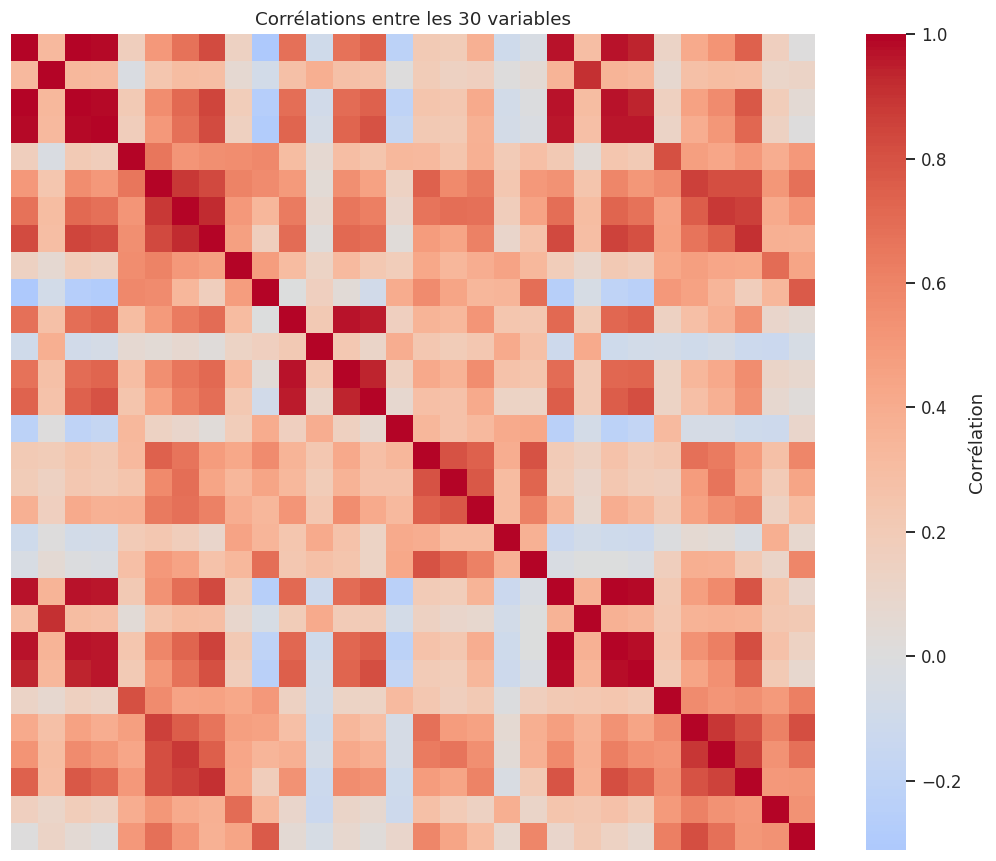

In [3]:
#fig:correlations
corr = X.corr()
plt.figure(figsize=(9.5, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False, cbar_kws={"label": "Corrélation"})
plt.title("Corrélations entre les 30 variables")
plt.tight_layout()

In [4]:
fortes = (corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack() > 0.9).sum()
print(f"{fortes} paires de variables ont une corrélation supérieure à 0,9 (en valeur absolue) sur {30 * 29 // 2} paires.")

21 paires de variables ont une corrélation supérieure à 0,9 (en valeur absolue) sur 435 paires.


Beaucoup de variables sont fortement corrélées (rayon, périmètre et aire d'une même tumeur mesurent presque la même chose) : c'est exactement la situation où l'ACP est utile.

## 2. ACP : résumer 30 variables en quelques axes

L'ACP cherche les directions qui expliquent le plus de variance. On l'applique aux variables **standardisées**.

In [5]:
Z = StandardScaler().fit_transform(X)
pca = PCA(random_state=RANDOM_STATE).fit(Z)
cumul = np.cumsum(pca.explained_variance_ratio_)
for seuil in (0.80, 0.90, 0.95):
    print(f"{int(np.argmax(cumul >= seuil)) + 1:2d} composantes pour expliquer {seuil:.0%} de la variance")
print(f"Axe 1 : {pca.explained_variance_ratio_[0]:.1%} | axe 2 : {pca.explained_variance_ratio_[1]:.1%} | les deux premiers : {cumul[1]:.1%}")

 5 composantes pour expliquer 80% de la variance
 7 composantes pour expliquer 90% de la variance
10 composantes pour expliquer 95% de la variance
Axe 1 : 44.3% | axe 2 : 19.0% | les deux premiers : 63.2%


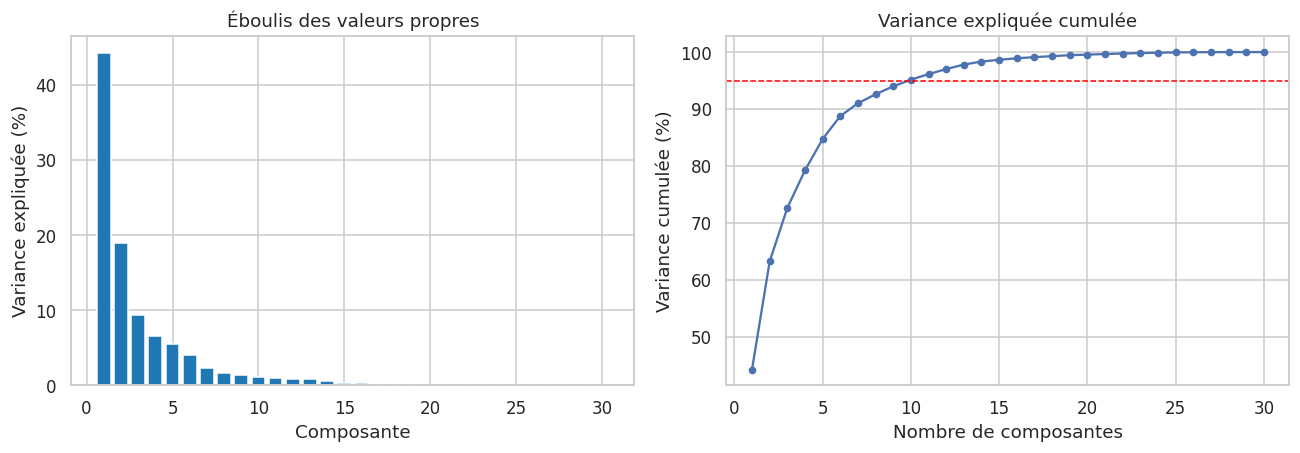

In [6]:
#fig:acp_variance
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].bar(range(1, 31), pca.explained_variance_ratio_ * 100, color="#1f77b4")
axes[0].set_xlabel("Composante"); axes[0].set_ylabel("Variance expliquée (%)"); axes[0].set_title("Éboulis des valeurs propres")
axes[1].plot(range(1, 31), cumul * 100, marker="o", ms=4)
axes[1].axhline(95, color="red", ls="--", lw=1)
axes[1].set_xlabel("Nombre de composantes"); axes[1].set_ylabel("Variance cumulée (%)"); axes[1].set_title("Variance expliquée cumulée")
plt.tight_layout()

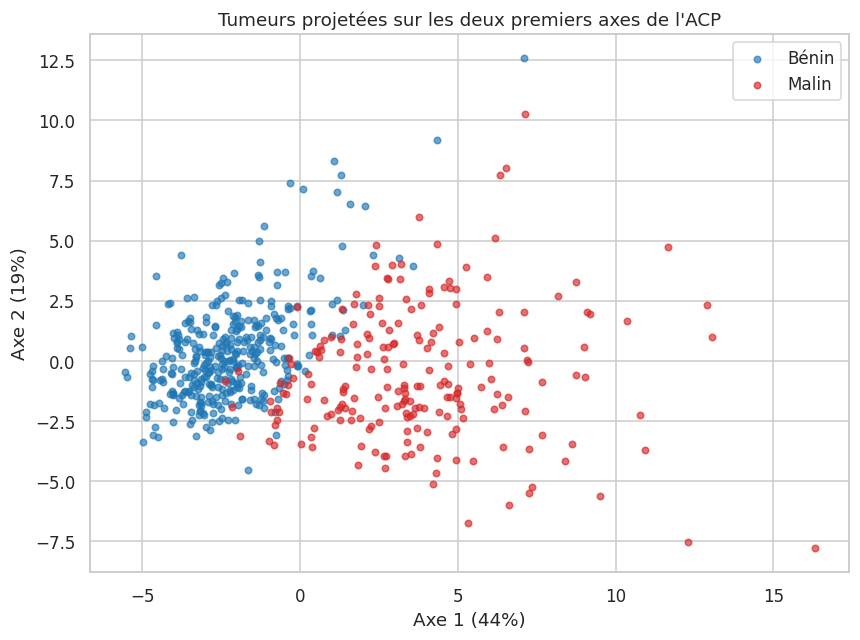

In [7]:
#fig:acp_plan
C = pca.transform(Z)[:, :2]
fig, ax = plt.subplots(figsize=(8, 6))
for val, nom, coul in [(0, "Bénin", "#1f77b4"), (1, "Malin", "#d62728")]:
    m = (y == val).values
    ax.scatter(C[m, 0], C[m, 1], s=18, alpha=0.65, label=nom, color=coul)
ax.set_xlabel(f"Axe 1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"Axe 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Tumeurs projetées sur les deux premiers axes de l'ACP")
ax.legend()
plt.tight_layout()

In [8]:
charges = pd.Series(pca.components_[0], index=X.columns)
top_charges = charges.reindex(charges.abs().sort_values(ascending=False).index).head(6)
print("Variables qui contribuent le plus à l'axe 1 (chargements, en valeur absolue décroissante) :")
print(top_charges.round(2).to_string())
print(f"Nombre de variables avec un chargement de même signe sur l'axe 1 : {int((charges > 0).sum())} sur 30")

Variables qui contribuent le plus à l'axe 1 (chargements, en valeur absolue décroissante) :
mean concave points    0.260
mean concavity         0.260
worst concave points   0.250
mean compactness       0.240
worst perimeter        0.240
worst concavity        0.230
Nombre de variables avec un chargement de même signe sur l'axe 1 : 30 sur 30


**Lecture.** Les 30 variables contribuent à l'axe 1 avec le même signe : c'est un axe de « taille et d'irrégularité globales » de la tumeur, auquel les mesures de concavité, de points concaves et de compacité contribuent le plus. Sept composantes suffisent pour conserver 90 % de la variance ; les deux premiers axes en résument 63 %, et la projection sur ce plan sépare déjà assez nettement les tumeurs bénignes des malignes.

**Effet de la standardisation :** on compare avec une ACP sur les données brutes.

In [9]:
pca_brut = PCA(random_state=RANDOM_STATE).fit(X)
print(f"ACP sur données brutes : l'axe 1 explique {pca_brut.explained_variance_ratio_[0]:.1%} de la variance (contre {pca.explained_variance_ratio_[0]:.1%} après standardisation)")
dom = pd.Series(np.abs(pca_brut.components_[0]), index=X.columns).sort_values(ascending=False).head(2)
print("Variables qui dominent l'axe 1 sans standardisation :", ", ".join(f"{n} ({v:.2f})" for n, v in dom.items()))

ACP sur données brutes : l'axe 1 explique 98.2% de la variance (contre 44.3% après standardisation)
Variables qui dominent l'axe 1 sans standardisation : worst area (0.85), mean area (0.52)


Sans standardisation, un seul axe capte presque toute la variance simplement parce que quelques variables (l'aire) ont des valeurs numériquement plus grandes : l'ACP ne reflète plus la structure des données mais leurs unités de mesure.

## 3. K-means : les données se regroupent-elles naturellement ?

K-means regroupe les observations en *k* groupes en minimisant la distance aux centres. C'est **non supervisé** : l'algorithme ne voit jamais le diagnostic. On l'utilise ensuite pour vérifier si les groupes trouvés correspondent à la réalité (indice de Rand ajusté, ARI : 1 = correspondance parfaite, 0 = hasard).

In [10]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    rows.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(Z, km.labels_)})
choix_k = pd.DataFrame(rows).set_index("k")
choix_k

,inertie,silhouette
k,,
2,"11,595.461",0.345
3,"10,061.798",0.314
4,"9,257.362",0.280
5,"8,557.727",0.159
6,"7,970.264",0.160
7,"7,540.319",0.153
8,"7,192.192",0.139


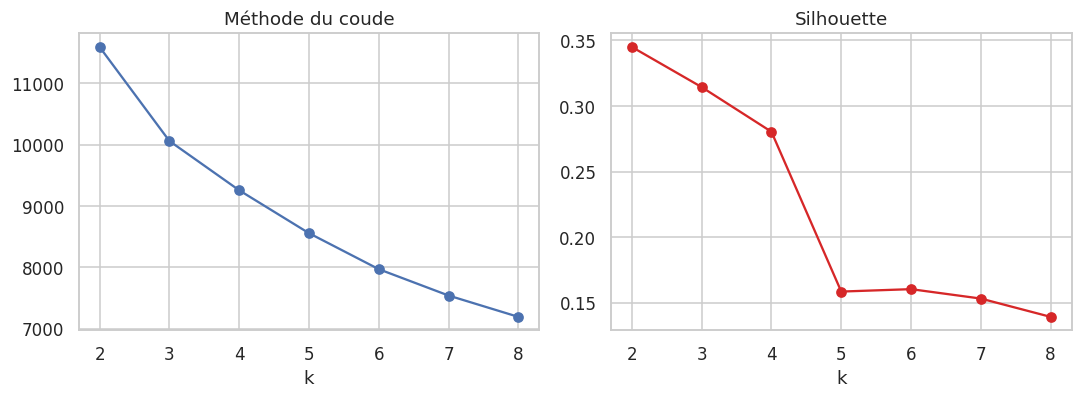

In [11]:
#fig:kmeans_choix_k
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(choix_k.index, choix_k.inertie, marker="o"); axes[0].set_title("Méthode du coude"); axes[0].set_xlabel("k")
axes[1].plot(choix_k.index, choix_k.silhouette, marker="o", color="#d62728"); axes[1].set_title("Silhouette"); axes[1].set_xlabel("k")
plt.tight_layout()

In [12]:
km2 = KMeans(n_clusters=2, n_init=20, random_state=RANDOM_STATE).fit(Z)
ct = pd.crosstab(pd.Series(km2.labels_, name="groupe K-means"), y.map({0: "bénin", 1: "malin"}).rename("diagnostic réel"))
ari = adjusted_rand_score(y, km2.labels_)
pureté = ct.max(axis=1).sum() / ct.values.sum()
print(f"k = 2 : silhouette = {silhouette_score(Z, km2.labels_):.2f} | ARI = {ari:.2f} | pureté des groupes = {pureté:.1%}")
ct

k = 2 : silhouette = 0.34 | ARI = 0.67 | pureté des groupes = 91.0%


diagnostic réel,bénin,malin
groupe K-means,,
0,14,175
1,343,37


**Lecture.** Sans jamais voir le diagnostic, K-means retrouve la structure bénin/malin : 91 % des tumeurs sont dans un groupe majoritairement du bon type (ARI = 0,67). Les 51 tumeurs restantes (14 bénignes dans le groupe « malin », 37 malignes dans le groupe « bénin ») se situent dans la zone de recouvrement visible sur le graphique ci-dessous. Le coefficient de silhouette (0,34, maximal pour k = 2) indique des groupes peu séparés et la méthode du coude ne montre pas de rupture nette : K-means est ici un outil d'exploration, pas un outil de diagnostic.

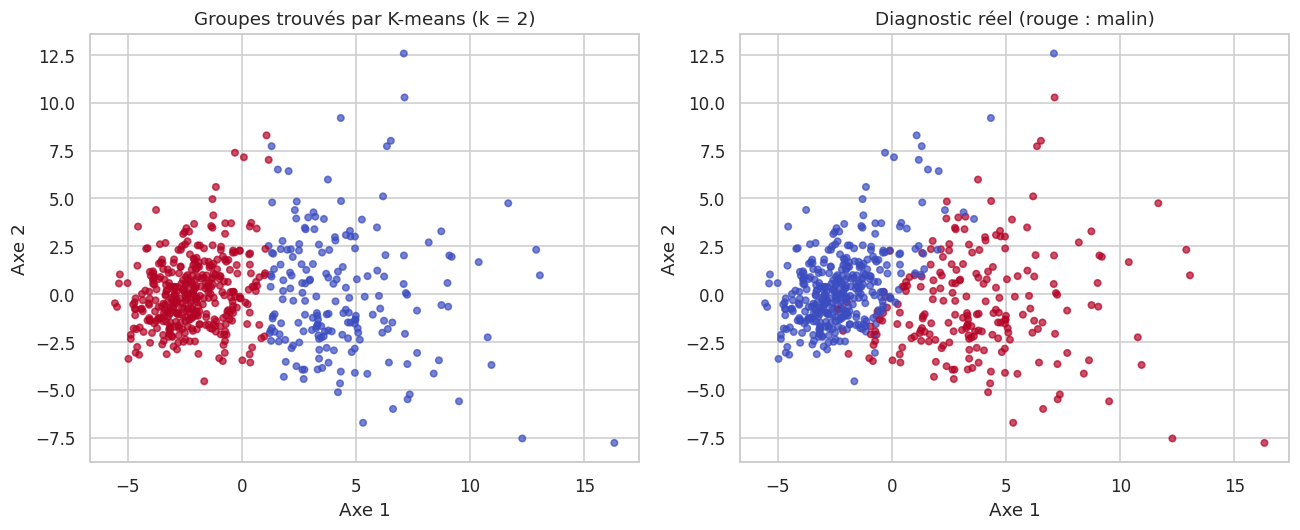

In [13]:
#fig:kmeans_acp
C = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(C[:, 0], C[:, 1], c=km2.labels_, cmap="coolwarm", s=18, alpha=0.7); axes[0].set_title("Groupes trouvés par K-means (k = 2)")
axes[1].scatter(C[:, 0], C[:, 1], c=y.values, cmap="coolwarm", s=18, alpha=0.7); axes[1].set_title("Diagnostic réel (rouge : malin)")
for ax in axes: ax.set_xlabel("Axe 1"); ax.set_ylabel("Axe 2")
plt.tight_layout()

## 4. k plus proches voisins : prédire le diagnostic

k-NN classe une tumeur d'après la majorité de ses *k* voisins les plus proches. Trois choix déterminent le résultat : le **nombre de voisins k**, la **distance** et la **standardisation**.

**Protocole :** séparation 75 % entraînement / 25 % test, stratifiée (mêmes proportions de tumeurs malignes). Le jeu de test n'est utilisé **qu'une seule fois, à la toute fin**. Tous les choix (k, distance) se font par validation croisée sur l'entraînement.

In [14]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"Entraînement : {len(X_tr)} | test : {len(X_te)} | part de tumeurs malignes : {y_tr.mean():.1%} (train), {y_te.mean():.1%} (test)")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Entraînement : 426 | test : 143 | part de tumeurs malignes : 37.3% (train), 37.1% (test)


### 4.1 Choix de k (validation croisée sur l'entraînement)
Le `StandardScaler` est placé **dans le pipeline** : il est recalculé sur chaque pli d'entraînement, ce qui évite qu'une information du pli de validation (moyenne, écart-type) ne fuite dans l'apprentissage.

In [15]:
ks = list(range(1, 31))
scores_k = {k: cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), X_tr, y_tr, cv=cv).mean() for k in ks}
scores_k = pd.Series(scores_k, name="exactitude CV")
k_opt = int(scores_k.idxmax())
print(f"Meilleur k = {k_opt} (exactitude en validation croisée = {scores_k.max():.3f})")
print(f"k = 1 : {scores_k[1]:.3f} | k = 5 : {scores_k[5]:.3f} | k = 15 : {scores_k[15]:.3f} | k = 30 : {scores_k[30]:.3f}")

Meilleur k = 3 (exactitude en validation croisée = 0.965)
k = 1 : 0.953 | k = 5 : 0.958 | k = 15 : 0.948 | k = 30 : 0.944


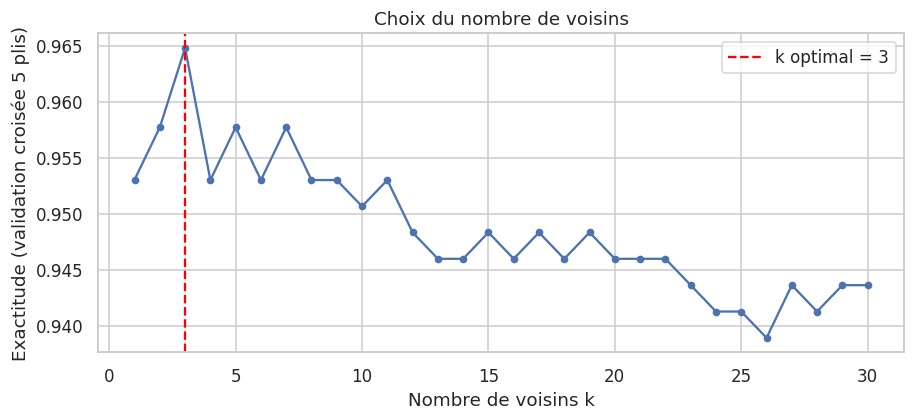

In [16]:
#fig:knn_choix_k
plt.figure(figsize=(8.5, 4))
plt.plot(scores_k.index, scores_k.values, marker="o", ms=4)
plt.axvline(k_opt, color="red", ls="--", label=f"k optimal = {k_opt}")
plt.xlabel("Nombre de voisins k"); plt.ylabel("Exactitude (validation croisée 5 plis)")
plt.title("Choix du nombre de voisins"); plt.legend()
plt.tight_layout()

**Lecture.** Les écarts entre valeurs de k sont faibles (de 0,944 à 0,965). Avec k = 1, le modèle colle au bruit des données (variance élevée) ; avec un k grand, il lisse trop (biais). Un petit k impair (3 à 5) donne ici le meilleur compromis.

### 4.2 Choix de la distance, et effet de la standardisation

In [17]:
metriques = {"Euclidienne": dict(metric="minkowski", p=2), "Manhattan": dict(metric="minkowski", p=1),
             "Minkowski (p = 3)": dict(metric="minkowski", p=3), "Tchebychev": dict(metric="chebyshev"),
             "Canberra": dict(metric="canberra")}
lignes = []
for nom, params in metriques.items():
    avec = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_opt, algorithm="brute", **params)), X_tr, y_tr, cv=cv).mean()
    sans = cross_val_score(KNeighborsClassifier(n_neighbors=k_opt, algorithm="brute", **params), X_tr, y_tr, cv=cv).mean()
    lignes.append({"Distance": nom, "Avec standardisation": avec, "Sans standardisation": sans})
dist = pd.DataFrame(lignes).set_index("Distance")
dist

,Avec standardisation,Sans standardisation
Distance,,
Euclidienne,0.965,0.937
Manhattan,0.972,0.946
Minkowski (p = 3),0.965,0.934
Tchebychev,0.946,0.925
Canberra,0.953,0.962


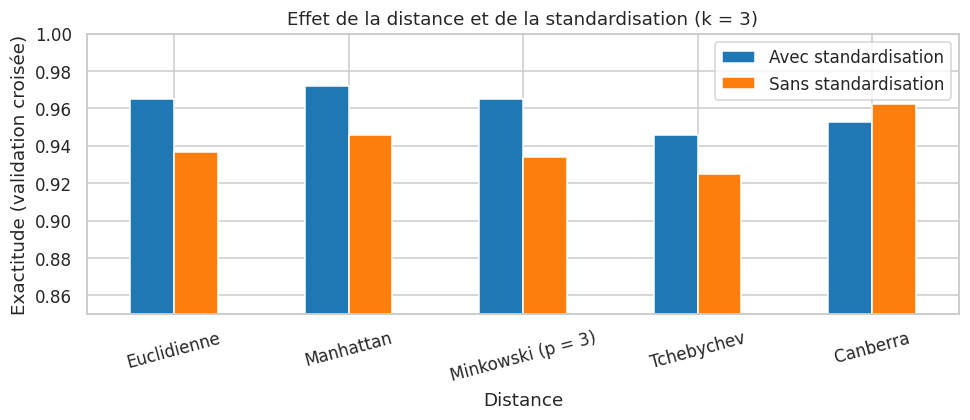

In [18]:
#fig:knn_distances
dist.plot.bar(figsize=(9, 4), rot=15, color=["#1f77b4", "#ff7f0e"])
plt.ylabel("Exactitude (validation croisée)"); plt.ylim(0.85, 1.0)
plt.title(f"Effet de la distance et de la standardisation (k = {k_opt})")
plt.tight_layout()

**Lecture.** La standardisation améliore le résultat pour 4 distances sur 5 (par exemple 0,965 contre 0,937 pour la distance euclidienne). Seule la distance de Canberra, qui normalise déjà chaque coordonnée, n'en bénéficie pas. Entre distances standardisées, les écarts sont inférieurs à un point (0,972 pour Manhattan contre 0,965 pour Euclidienne, soit 3 tumeurs sur 426) : ils sont du même ordre que le bruit statistique. Le choix de Manhattan est raisonnable, pas démontré supérieur.

### 4.3 Évaluation finale sur le jeu de test
On retient le modèle (k et distance) choisi par validation croisée, on le réentraîne sur tout l'entraînement et on l'évalue une seule fois sur le test. En contexte médical, une tumeur maligne classée bénigne (faux négatif) est l'erreur la plus grave : on suit donc la **sensibilité** (part des tumeurs malignes détectées) autant que l'exactitude.

In [19]:
dist_opt = dist["Avec standardisation"].idxmax()
modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_opt, algorithm="brute", **metriques[dist_opt]))
modele.fit(X_tr, y_tr)
pred = modele.predict(X_te)
proba = modele.predict_proba(X_te)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
print(f"Modèle : k = {k_opt}, distance {dist_opt}")
print(f"Exactitude : {accuracy_score(y_te, pred):.3f} | Sensibilité (malins détectés) : {recall_score(y_te, pred):.3f} | "
      f"Précision : {precision_score(y_te, pred):.3f} | AUC : {roc_auc_score(y_te, proba):.3f}")
print(f"Faux négatifs : {fn} sur {tp + fn} tumeurs malignes | Faux positifs : {fp} sur {tn + fp} tumeurs bénignes")

Modèle : k = 3, distance Manhattan
Exactitude : 0.972 | Sensibilité (malins détectés) : 0.925 | Précision : 1.000 | AUC : 0.979
Faux négatifs : 4 sur 53 tumeurs malignes | Faux positifs : 0 sur 90 tumeurs bénignes


In [20]:
def intervalle_wilson(succes, n, z=1.96):
    """Intervalle de confiance à 95 % (méthode de Wilson) d'une proportion."""
    p = succes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    demi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - demi, centre + demi

lo, hi = intervalle_wilson(tp, tp + fn)
print(f"Sensibilité : {tp}/{tp + fn} = {tp / (tp + fn):.1%}, intervalle de confiance à 95 % : [{lo:.1%} ; {hi:.1%}]")
lo, hi = intervalle_wilson(tp + tn, len(y_te))
print(f"Exactitude  : {tp + tn}/{len(y_te)} = {(tp + tn) / len(y_te):.1%}, intervalle de confiance à 95 % : [{lo:.1%} ; {hi:.1%}]")

Sensibilité : 49/53 = 92.5%, intervalle de confiance à 95 % : [82.1% ; 97.0%]
Exactitude  : 139/143 = 97.2%, intervalle de confiance à 95 % : [93.0% ; 98.9%]


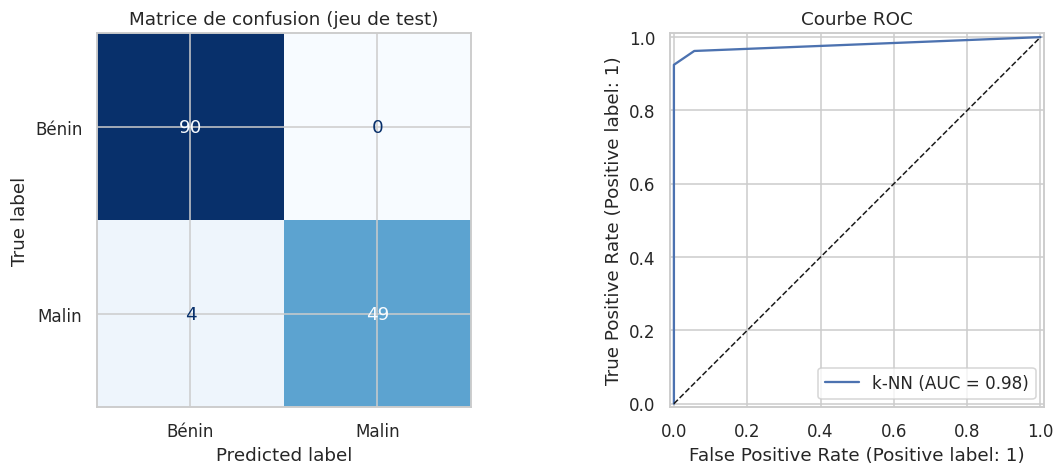

In [21]:
#fig:knn_test
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["Bénin", "Malin"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Matrice de confusion (jeu de test)")
RocCurveDisplay.from_predictions(y_te, proba, ax=axes[1], name="k-NN")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("Courbe ROC")
plt.tight_layout()

**Lecture.** Sur le jeu de test, le modèle obtient 97,2 % d'exactitude, aucun faux positif, mais 4 tumeurs malignes sur 53 non détectées (sensibilité de 92,5 %). Avec seulement 143 tumeurs, l'incertitude est large : l'intervalle de confiance à 95 % de la sensibilité va de 82 % à 97 %. En contexte clinique, on privilégierait un seuil de décision favorisant la sensibilité, quitte à accepter plus de faux positifs, qui seraient levés par des examens complémentaires. Ce notebook est un exercice méthodologique, pas un outil d'aide au diagnostic.

## 5. ACP puis k-NN : réduire la dimension aide-t-il ?
On insère une ACP dans le pipeline et on fait varier le nombre de composantes conservées. L'ACP est elle aussi recalculée sur chaque pli d'entraînement.

In [22]:
comps = [1, 2, 3, 5, 7, 10, 15, 20, 30]
sc_pca = {n: cross_val_score(make_pipeline(StandardScaler(), PCA(n_components=n, random_state=RANDOM_STATE),
                                           KNeighborsClassifier(n_neighbors=k_opt)), X_tr, y_tr, cv=cv).mean() for n in comps}
sc_pca = pd.Series(sc_pca, name="exactitude CV")
print(f"Meilleur nombre de composantes : {sc_pca.idxmax()} ({sc_pca.max():.3f}) | toutes les variables (30) : {sc_pca[30]:.3f} | 2 composantes : {sc_pca[2]:.3f}")
sc_pca.to_frame()

Meilleur nombre de composantes : 30 (0.965) | toutes les variables (30) : 0.965 | 2 composantes : 0.920


,exactitude CV
1,0.890
2,0.920
3,0.925
5,0.960
7,0.965
10,0.962
15,0.962
20,0.962
30,0.965


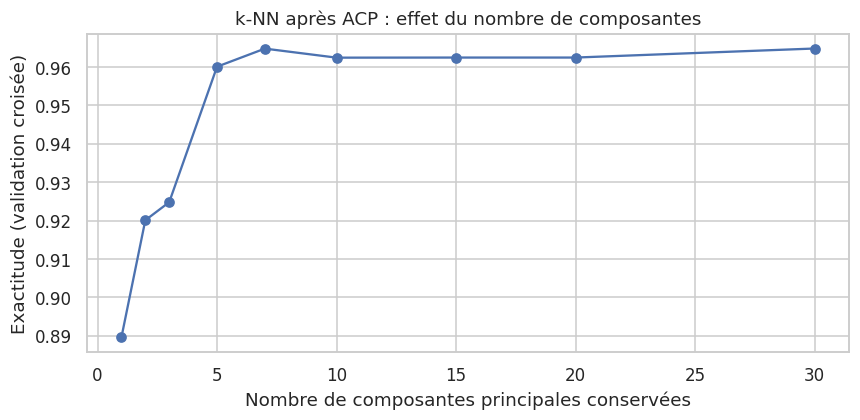

In [23]:
#fig:acp_knn
plt.figure(figsize=(8, 4))
plt.plot(sc_pca.index, sc_pca.values, marker="o")
plt.xlabel("Nombre de composantes principales conservées"); plt.ylabel("Exactitude (validation croisée)")
plt.title("k-NN après ACP : effet du nombre de composantes")
plt.tight_layout()

**Lecture.** Conserver 7 composantes (90 % de la variance) donne la même exactitude que les 30 variables (0,965) : la dimension est divisée par 4 sans perte mesurable. Avec 2 composantes seulement, l'exactitude tombe à 0,920, et à 0,890 avec une seule : l'information utile est répartie sur plusieurs axes.

## 6. Comparaison avec un modèle de référence et incertitude

Une exactitude sur un seul jeu de test de 143 tumeurs est une estimation **bruitée** : quelques observations changent le résultat de plusieurs points. On répète donc la validation croisée 10 fois (5 plis, 50 évaluations) et on compare à une **régression logistique**, modèle de référence classique. Pour que la comparaison soit honnête, le réglage des hyperparamètres (k et distance pour le k-NN, paramètre de régularisation C pour la régression logistique) est refait **à l'intérieur** de chaque pli d'entraînement (*validation croisée imbriquée*) : aucune information du pli de test n'influence le choix du modèle.

In [24]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
interne = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
# Validation croisée imbriquée : le réglage des hyperparamètres est refait à l'intérieur de chaque pli d'entraînement
knn_gs = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                      {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21], "kneighborsclassifier__p": [1, 2]}, cv=interne)
log_gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                      {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}, cv=interne)
candidats = {"k-NN (k et distance réglés)": knn_gs, "Régression logistique (C réglé)": log_gs}
res = {nom: cross_val_score(m, X, y, cv=rcv, scoring="accuracy") for nom, m in candidats.items()}
tab = pd.DataFrame({nom: {"Exactitude moyenne": s.mean(), "Écart-type": s.std(), "Min": s.min(), "Max": s.max()} for nom, s in res.items()}).T
print(f"{len(next(iter(res.values())))} évaluations par modèle")
tab

50 évaluations par modèle


,Exactitude moyenne,Écart-type,Min,Max
k-NN (k et distance réglés),0.967,0.014,0.939,0.991
Régression logistique (C réglé),0.977,0.014,0.947,1.000


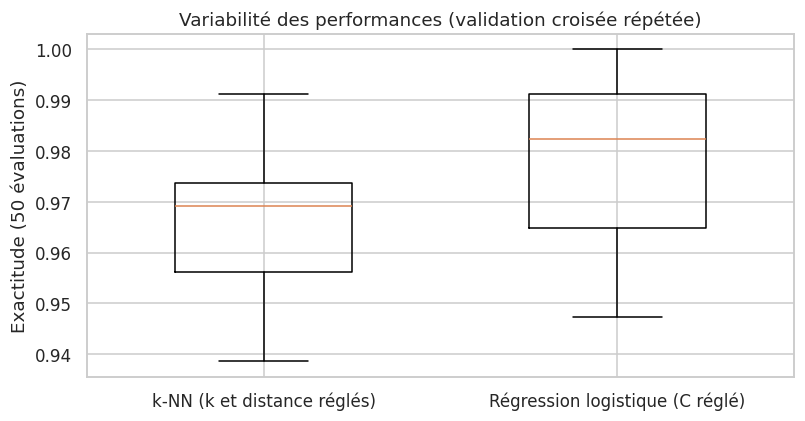

In [25]:
#fig:comparaison_modeles
plt.figure(figsize=(7.5, 4))
plt.boxplot([res[n] for n in res], widths=0.5)
plt.xticks(range(1, len(res) + 1), list(res))
plt.ylabel("Exactitude (50 évaluations)")
plt.title("Variabilité des performances (validation croisée répétée)")
plt.tight_layout()

**Lecture.** La régression logistique (97,7 % en moyenne) est légèrement meilleure que le k-NN (96,7 %), avec la même dispersion (écart-type de 1,4 point). Un modèle simple et interprétable est donc compétitif, voire meilleur, sur ce jeu de données : le k-NN n'apporte pas de gain ici, et un écart d'un point reste modeste au regard de la variabilité d'une évaluation à l'autre (de 0,939 à 0,991 pour le k-NN).

## 7. Quelles mesures pèsent dans la décision ? (importance par permutation)
Pour un modèle k-NN, il n'y a pas de coefficients à lire. L'importance par permutation mesure la **baisse de performance** quand on mélange aléatoirement une variable du jeu de test : plus la baisse est forte, plus le modèle s'appuie sur cette variable.

In [26]:
imp = permutation_importance(modele, X_te, y_te, n_repeats=30, random_state=RANDOM_STATE, scoring="accuracy")
imp = pd.DataFrame({"importance": imp.importances_mean, "écart-type": imp.importances_std}, index=X.columns).sort_values("importance", ascending=False)
imp.head(8)

,importance,écart-type
worst radius,0.014,0.004
worst perimeter,0.014,0.007
worst area,0.014,0.004
mean concavity,0.008,0.007
mean concave points,0.007,0.005
worst concave points,0.007,0.003
mean fractal dimension,0.007,0.006
worst smoothness,0.007,0.004


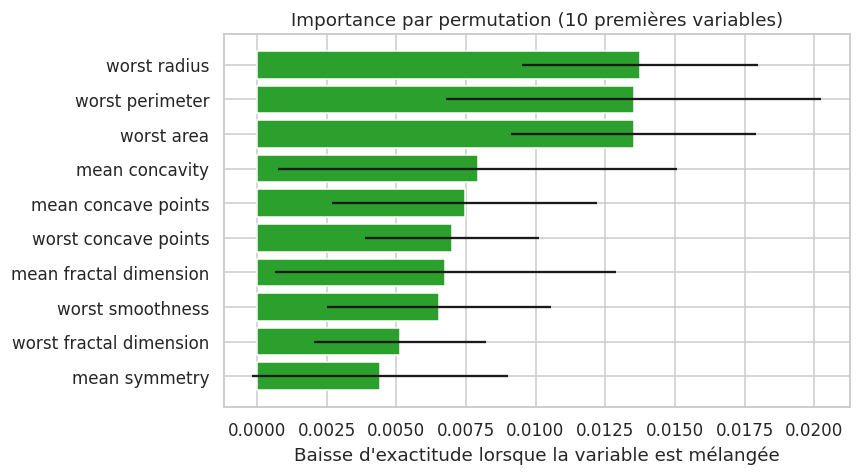

In [27]:
#fig:importance
top = imp.head(10)[::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(top.index, top["importance"], xerr=top["écart-type"], color="#2ca02c")
plt.xlabel("Baisse d'exactitude lorsque la variable est mélangée")
plt.title("Importance par permutation (10 premières variables)")
plt.tight_layout()

**Lecture.** Les variables les plus importantes sont les mesures de taille « worst » (rayon, périmètre, aire), mais leur importance individuelle est faible (environ 1,4 point d'exactitude). Ces variables sont presque redondantes entre elles : mélanger l'une d'elles est compensé par les autres. L'importance par permutation sous-estime donc le rôle de groupes de variables corrélées ; on ne peut pas conclure que les variables moins bien classées sont inutiles.

## 8. Même démarche sur le jeu Iris
Iris (150 fleurs, 4 mesures, 3 espèces) est le jeu d'école de la classification. On y reprend rapidement les trois méthodes pour comparer.

In [28]:
iris = load_iris(as_frame=True)
Xi, yi = iris.data, iris.target
Zi = StandardScaler().fit_transform(Xi)
pi = PCA(random_state=RANDOM_STATE).fit(Zi)
print("ACP : variance expliquée par axe :", np.round(pi.explained_variance_ratio_, 3), "| 2 premiers axes :", f"{pi.explained_variance_ratio_[:2].sum():.1%}")
ki = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE).fit(Zi)
print(f"K-means (k = 3) vs espèces : ARI = {adjusted_rand_score(yi, ki.labels_):.2f}, silhouette = {silhouette_score(Zi, ki.labels_):.2f}")
cvi = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
lignes = {nom: cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, algorithm="brute", **p)), Xi, yi, cv=cvi).mean()
          for nom, p in metriques.items()}
print("k-NN (k = 7), exactitude en validation croisée selon la distance :")
pd.Series(lignes, name="exactitude").to_frame()

ACP : variance expliquée par axe : [0.73  0.229 0.037 0.005] | 2 premiers axes : 95.8%
K-means (k = 3) vs espèces : ARI = 0.62, silhouette = 0.46
k-NN (k = 7), exactitude en validation croisée selon la distance :


,exactitude
Euclidienne,0.960
Manhattan,0.940
Minkowski (p = 3),0.973
Tchebychev,0.947
Canberra,0.940


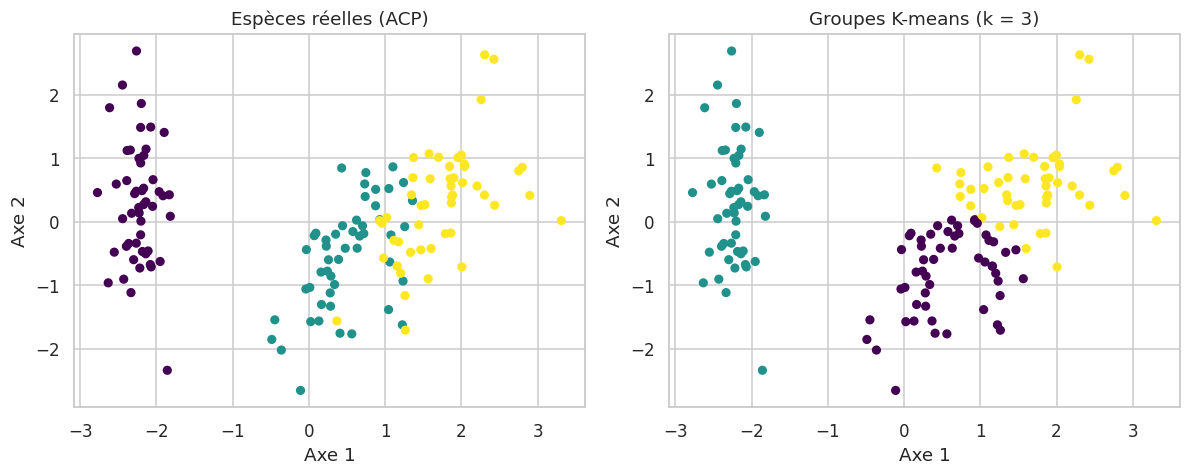

In [29]:
#fig:iris
Ci = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Zi)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(Ci[:, 0], Ci[:, 1], c=yi, cmap="viridis", s=25); axes[0].set_title("Espèces réelles (ACP)")
axes[1].scatter(Ci[:, 0], Ci[:, 1], c=ki.labels_, cmap="viridis", s=25); axes[1].set_title("Groupes K-means (k = 3)")
for ax in axes: ax.set_xlabel("Axe 1"); ax.set_ylabel("Axe 2")
plt.tight_layout()

**Lecture.** Sur Iris, deux axes d'ACP résument 95,8 % de la variance. K-means retrouve les trois espèces avec un ARI de 0,62 (silhouette de 0,46) : une espèce est bien isolée, les deux autres se chevauchent. Avec 150 fleurs seulement, les différences entre distances (0,940 à 0,973) sont du même ordre que le bruit : on ne peut pas désigner de distance meilleure.

## 9. Conclusions et limites

**Ce que montrent les résultats**
- **ACP :** 7 composantes sur 30 conservent 90 % de la variance, et l'exactitude du k-NN reste la même après cette réduction. La standardisation est indispensable : sans elle, un seul axe capte 98 % de la variance, uniquement à cause de l'échelle de l'aire.
- **K-means :** retrouve la structure bénin/malin à 91 % sans connaître le diagnostic (ARI de 0,67), mais les groupes se chevauchent (silhouette de 0,34).
- **k-NN :** 97,2 % d'exactitude sur le jeu de test (intervalle de confiance à 95 % : 93 % à 99 %), sensibilité de 92,5 % (82 % à 97 %). En validation croisée imbriquée répétée, la régression logistique (97,7 %) fait légèrement mieux que le k-NN (96,7 %).

**Limites**
- Un seul jeu de données de petite taille (569 tumeurs) ; les variables sont des mesures déjà extraites d'images, et aucune validation externe (autre hôpital, autre période) n'est possible ici.
- Un résultat de 97 % sur ce jeu ne garantit pas un résultat comparable en pratique clinique, où les données sont plus hétérogènes et le coût d'un faux négatif très élevé.
- Les écarts entre distances ou entre modèles proches sont de l'ordre du bruit statistique.
- Pas d'optimisation de seuil de décision ni de calibration des probabilités.

**Pistes d'amélioration :** choisir le seuil de décision selon un coût clinique, ajouter d'autres modèles (SVM, forêt aléatoire, gradient boosting), calibrer les probabilités, tester sur un jeu externe.